# Classical Classification of Roud Song Clusters

Uses three classifiers:
K-nearest neighbors (KNN), a support vector machine (SVM) and linear discriminant analysis (LDA).

In [1]:
import numpy as np
import pandas as pd

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, adjusted_rand_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

SEED = 1337  # for determinism

In [2]:
# Load the data, drop duplicates and any songs without lyrics
raw = pd.read_csv("dataset-v2.csv", dtype=str)

df_lyrics2 = pd.DataFrame({
    "name":    raw["title"],
    "roud":    raw["roud"],   # the answer we're evaluating
    "variant": raw["title"] + "# " + raw["version"],
    "lyrics":  raw["lyrics"],
})

df_lyrics2 = df_lyrics2.dropna(subset=["lyrics", "roud"])
df_lyrics2 = df_lyrics2.drop_duplicates(subset=["name", "lyrics", "roud"]).reset_index(drop=True)

print(len(df_lyrics2), "versions of", df_lyrics2.roud.nunique(), "songs")
df_lyrics2.head()

6828 versions of 2167 songs


,name,roud,variant,lyrics
0,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 1,"It being on the twenty-third of June-o,\nAs I ..."
1,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 2,As I was sitting with my glass and spoon\nOne ...
2,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 3,"It being on the third of June,\nas I sat weavi..."
3,A Jug of Punch / The 23 rd of June,1808,A Jug of Punch / The 23 rd of June# 4,As I was sitting with my jug and spoon\nOn one...
4,A Maid in Bedlam / Abroad As I Was Walking,578,A Maid in Bedlam / Abroad As I Was Walking# 1,Abroad as I was walking one evening in the spr...


In [3]:
# Keep ballads of three versions, so every fold below can train and test on each ballad
df_lyrics2["roud_count"] = df_lyrics2.groupby("roud")["roud"].transform("count")
df_roud_multiples = df_lyrics2[df_lyrics2["roud_count"] >= 3].reset_index(drop=True)
print(len(df_roud_multiples), "variants of", df_roud_multiples.roud.nunique(), "ballads kept")

5023 variants of 887 ballads kept


Each song is predicted once by models that never saw it (3-fold cross-validation). The TF-IDF step sits inside each
pipeline, so its vocabulary also comes from the training songs only.

- **KNN** predicts the ballad of the most similar songs, using the same cosine distance as the TF-IDF clustering notebook.
- **SVM** learns a linear boundary between each ballad and the rest.
- **LDA** can't use the huge sparse TF-IDF matrix directly, so TruncatedSVD compresses it to 300 dimensions first.

In [4]:
# shared setup: tf-idf settings, and the same 3 folds for every model
tfidf_params = dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                    strip_accents="unicode", dtype=np.float32)

lyrics = df_roud_multiples["lyrics"].to_numpy()
roud = df_roud_multiples["roud"].to_numpy()
folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(lyrics, roud))

df_pred = df_roud_multiples.copy()

In [5]:
# KNN: predict the ballad of the most similar songs
knn = make_pipeline(TfidfVectorizer(**tfidf_params),
                    KNeighborsClassifier(n_neighbors=3, metric="cosine", weights="distance"))
df_pred["pred_knn"] = cross_val_predict(knn, lyrics, roud, cv=folds)
print(f"KNN accuracy: {accuracy_score(roud, df_pred['pred_knn']):.3f}")

KNN accuracy: 0.968


In [6]:
# SVM: learn a linear boundary between each ballad and the rest
svm = make_pipeline(TfidfVectorizer(**tfidf_params), LinearSVC(random_state=SEED))
df_pred["pred_svm"] = cross_val_predict(svm, lyrics, roud, cv=folds)
print(f"SVM accuracy: {accuracy_score(roud, df_pred['pred_svm']):.3f}")

SVM accuracy: 0.974


In [7]:
# LDA: compress tf-idf to 300 dimensions first, since LDA can't use the sparse matrix directly
lda = make_pipeline(TfidfVectorizer(**tfidf_params), TruncatedSVD(n_components=300, random_state=SEED),
                    LinearDiscriminantAnalysis())
df_pred["pred_lda"] = cross_val_predict(lda, lyrics, roud, cv=folds)
print(f"LDA accuracy: {accuracy_score(roud, df_pred['pred_lda']):.3f}")

LDA accuracy: 0.868



- **Accuracy** = share of songs given the correct Roud number. **Macro F1** averages the score over ballads, so rare ballads count as much as common ones.
- **Macro precision** = when a model predicts a ballad, how often it is right, averaged over ballads. Low precision goes with mixed clusters.
- **Macro recall** = how many of a ballad's songs the model finds, averaged over ballads. Low recall goes with split ballads.


In [11]:
# how good are the predictions?
def score_model(name, pred_col):
    pred = df_pred[pred_col].to_numpy()
    per_cluster = df_pred.groupby(pred_col)["roud"].nunique()
    per_ballad  = df_pred.groupby("roud")[pred_col].nunique()
    fold_acc = [accuracy_score(roud[test_idx], pred[test_idx]) for _, test_idx in folds]
    return {
        "model": name,
        "accuracy": accuracy_score(roud, pred),
        "accuracy_fold_std": np.std(fold_acc),
        "macro_f1": f1_score(roud, pred, average="macro", zero_division=0),
        "macro_precision": precision_score(roud, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(roud, pred, average="macro", zero_division=0),
        "ARI": adjusted_rand_score(roud, pred),
        "pure_clusters": (per_cluster == 1).sum(),
        "mixed_clusters": (per_cluster > 1).sum(),
        "split_ballads": (per_ballad > 1).sum(),
    }

df_results = pd.DataFrame([
    score_model("KNN", "pred_knn"),
    score_model("SVM", "pred_svm"),
    score_model("LDA", "pred_lda"),
]).set_index("model").round(3)
df_results

,accuracy,accuracy_fold_std,macro_f1,macro_precision,macro_recall,ARI,pure_clusters,mixed_clusters,split_ballads
model,,,,,,,,,
KNN,0.968,0.002,0.962,0.969,0.962,0.941,766,116,116
SVM,0.974,0.002,0.970,0.978,0.967,0.948,786,98,101
LDA,0.868,0.010,0.889,0.936,0.869,0.598,752,133,440


In [12]:
#t-sne, turning many dimensions into two. This is only for drawing the chart: the models above don't use it

vectorizer = TfidfVectorizer(**tfidf_params)
X = vectorizer.fit_transform(lyrics)

X_dist = np.clip(1.0 - X.dot(X.T).toarray(), 0.0, None)
X_dist = (X_dist + X_dist.T) / 2
np.fill_diagonal(X_dist, 0.0)

X_tsne = TSNE(n_components=2, metric="precomputed", init="random", random_state=SEED, n_jobs=-1).fit_transform(X_dist)
df_pred["tsne"] = X_tsne.tolist()
df_pred[["name", "roud", "tsne"]].head()

,name,roud,tsne
0,A Jug of Punch / The 23 rd of June,1808,"[30.460075, -45.934883]"
1,A Jug of Punch / The 23 rd of June,1808,"[30.530083, -44.938114]"
2,A Jug of Punch / The 23 rd of June,1808,"[30.471596, -45.755547]"
3,A Jug of Punch / The 23 rd of June,1808,"[30.49386, -45.520935]"
4,A Maid in Bedlam / Abroad As I Was Walking,578,"[14.264931, 51.624977]"


In [13]:
# chart/plot: where each model went wrong, and how evenly it did across ballads
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

def plot_model(name, pred_col):
    pred = df_pred[pred_col].to_numpy()
    correct = pred == roud

    fig, (ax_map, ax_f1) = plt.subplots(1, 2, figsize=(14, 6), width_ratios=[3, 2])
    fig.suptitle(f"{name}: {correct.mean():.1%} of songs predicted correctly")

    # wrong songs are drawn last so the correct ones can't hide them
    ax_map.scatter(X_tsne[correct, 0], X_tsne[correct, 1], s=8, linewidths=0, color="#c9c8c2",
                   label=f"Correct ({correct.sum()})")
    ax_map.scatter(X_tsne[~correct, 0], X_tsne[~correct, 1], s=14, linewidths=0, color="#eb6834",
                   label=f"Wrong ({(~correct).sum()})")
    ax_map.set_aspect("equal")
    ax_map.set_xlabel("t-SNE X")
    ax_map.set_ylabel("t-SNE Y")
    ax_map.legend(frameon=False, loc="upper right")

    ballad_f1 = f1_score(roud, pred, labels=np.unique(roud), average=None, zero_division=0)
    ax_f1.hist(ballad_f1, bins=np.linspace(0, 1, 11), color="#2a78d6", edgecolor="white", linewidth=2)
    ax_f1.set_xlabel("F1 score of the ballad")
    ax_f1.set_ylabel("Number of ballads")
    ax_f1.grid(axis="y", color="#e8e7e2")
    ax_f1.set_axisbelow(True)

    fig.tight_layout()
    fig.savefig(f"ballad_predictions_{name.lower()}.png", dpi=200)
    plt.show()

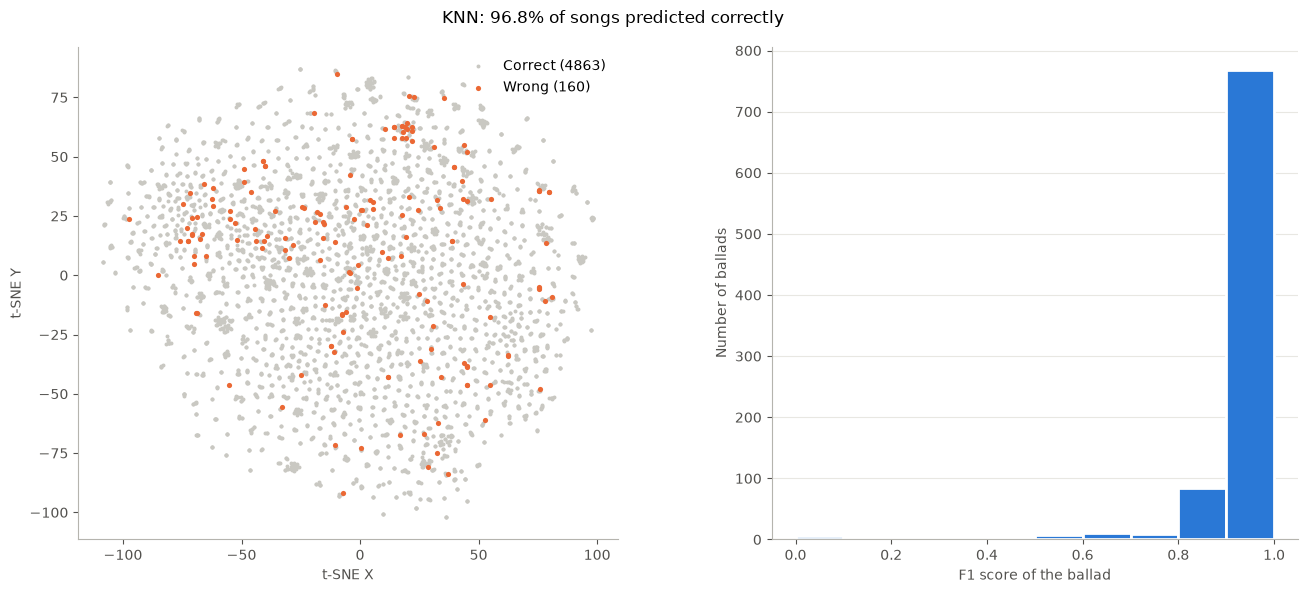

In [14]:
plot_model("KNN", "pred_knn")

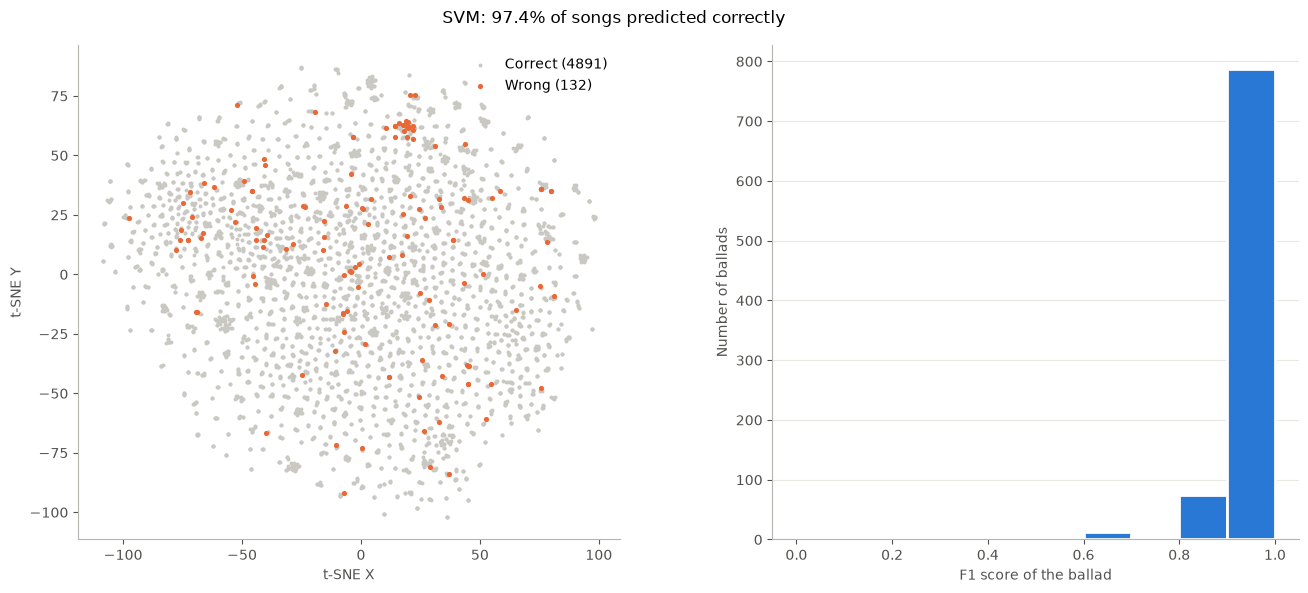

In [15]:
plot_model("SVM", "pred_svm")

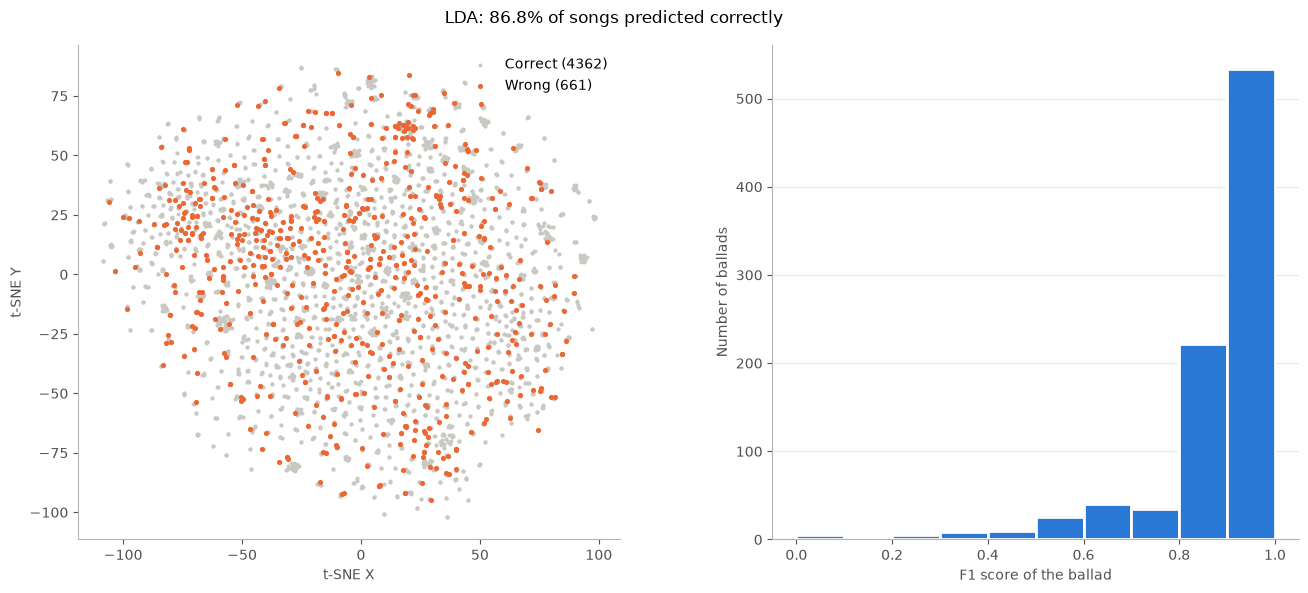

In [16]:
plot_model("LDA", "pred_lda")

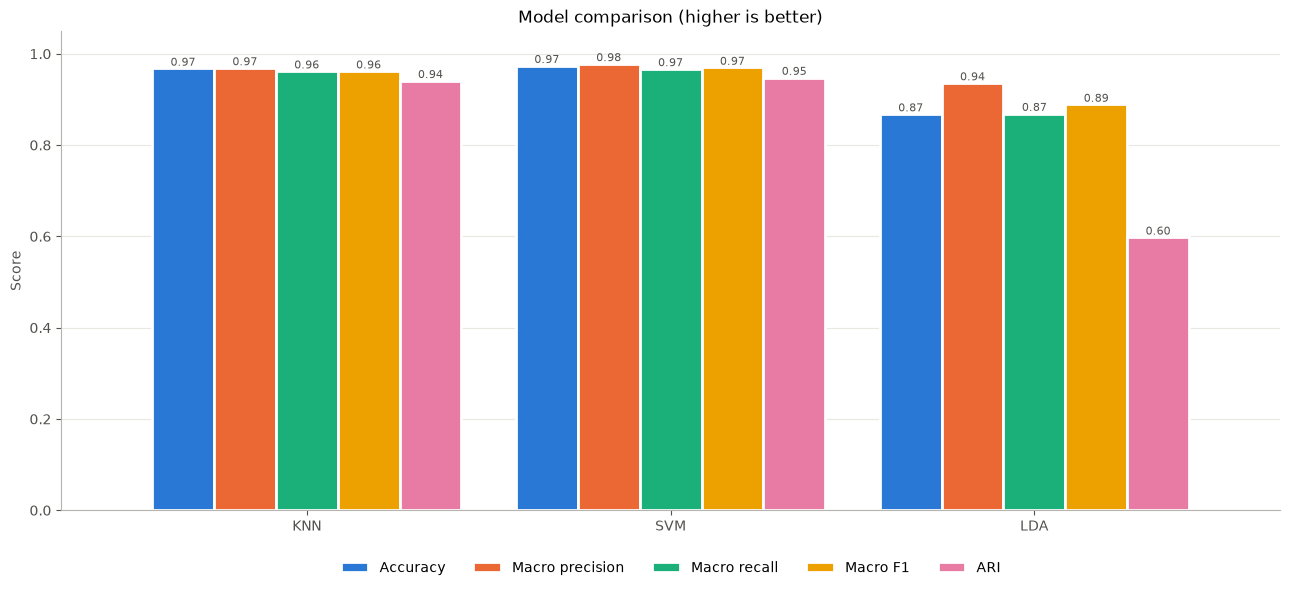

In [17]:
# compare all of the models on one chart
ax = df_results[["accuracy", "macro_precision", "macro_recall", "macro_f1", "ARI"]].plot.bar(
    figsize=(13, 6), width=0.85, edgecolor="white", linewidth=2,
    color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", color="#52514e", fontsize=8)

ax.set_title("Model comparison (higher is better)")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", color="#e8e7e2")
ax.set_axisbelow(True)
ax.legend(["Accuracy", "Macro precision", "Macro recall", "Macro F1", "ARI"], frameon=False, ncols=5,
          loc="upper center", bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig("ballad_predictions_comparison.png", dpi=200)
plt.show()

## Standard charts for each model

The classic versions of these charts assume a few classes in two dimensions, but here there are 887 ballads and a huge vocabulary of word scores.
So most of them focus on the largest ballads.

- **LDA scatter:** songs on LDA's first two axes, colored by ballad. Fitted on just the 3 largest ballads, so it shows a smaller model than the one scored above.
- **KNN accuracy vs k:** the full model's accuracy with different numbers of neighbors. Accuracy falls as k grows because most ballads are small (the median has 4 versions), so with a large k most neighbors must come from other ballads. These are the same test songs used for the scores above, so choosing k from this chart would make KNN's score slightly optimistic.
- **SVM scores:** the full data, for one ballad against every other song. Songs far from the boundary at 0 are the clear-cut ones.
- **SVM boundaries:** the classic picture. It needs a separate SVM trained on only 2 dimensions, so **it's an illustration** and its accuracy isn't the model's accuracy.
- **Confusion matrices:** the real predictions from above, for the 10 largest ballads. They show where these ballads' songs went wrong, but not songs from other ballads wrongly predicted as one of these. **These ballads have the most training songs, so they look better than the overall scores:** the table above is the fair summary of each model.

The two scatter charts only draw test songs. There are far more word scores than these ballads have songs, and LDA can separate its training songs perfectly just by overfitting, so drawing those would make it look better than it is.
These charts use TruncatedSVD for the 2 dimensions rather than t-SNE, because t-SNE bends distances and a straight SVM boundary wouldn't mean much on its map.

In [18]:
from sklearn.metrics import confusion_matrix

In [19]:
# Most of these charts can't show 887 ballads at once, so they use the ballads with the most versions
version_counts = df_pred["roud"].value_counts()
top_10_ballads = version_counts.index[:10].to_numpy()
top_3_ballads = top_10_ballads[:3]

# A short name for each ballad: the first title in its list of titles
ballad_names = {}
for ballad in top_10_ballads:
    full_title = df_pred.loc[df_pred["roud"] == ballad, "name"].iloc[0]
    ballad_names[ballad] = full_title.split(" / ")[0]

# Each ballad keeps the same color and marker shape on every chart
ballad_colors = dict(zip(top_3_ballads, ["#2a78d6", "#eb6834", "#1baf7a"]))
ballad_markers = dict(zip(top_3_ballads, ["o", "s", "^"]))

# The scatter charts train on one fold's training songs and only draw its test songs
train_idx, test_idx = folds[0]
is_top_3 = np.isin(roud, top_3_ballads)
train_top_3 = train_idx[is_top_3[train_idx]]
test_top_3 = test_idx[is_top_3[test_idx]]
train_labels = roud[train_top_3]
test_labels = roud[test_top_3]
print("top 3 ballads:", len(train_top_3), "training songs,", len(test_top_3), "test songs")


# Draw the given songs on a chart, one color and marker shape per ballad
def draw_songs(ax, points, labels):
    for ballad in top_3_ballads:
        is_this_ballad = labels == ballad
        ax.scatter(points[is_this_ballad, 0], points[is_this_ballad, 1],
                   s=70, color=ballad_colors[ballad], marker=ballad_markers[ballad],
                   edgecolors="white", linewidths=1.5,
                   label=f"{ballad_names[ballad]} (Roud {ballad})")


top 3 ballads: 77 training songs, 36 test songs


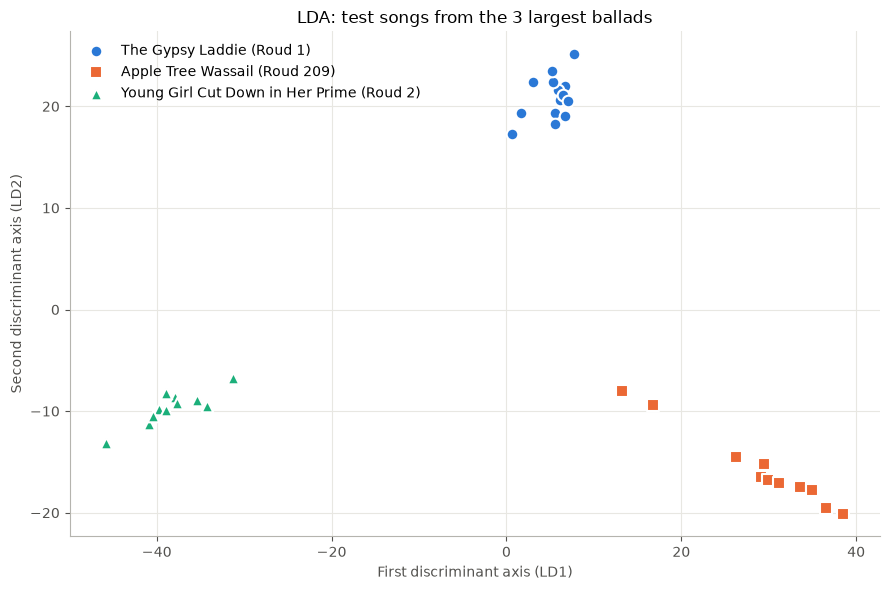

In [20]:
# LDA chart: fit on the training songs of the top 3 ballads, then move the test songs onto LDA's two best axes
# As above, TF-IDF has to be compressed first. These few songs only allow a smaller compression than 300
lda_top_3 = make_pipeline(TfidfVectorizer(**tfidf_params), TruncatedSVD(n_components=50, random_state=SEED),
                          LinearDiscriminantAnalysis(n_components=2))
lda_top_3.fit(lyrics[train_top_3], train_labels)
test_points = lda_top_3.transform(lyrics[test_top_3])

# Draw the test songs on the two new axes
fig, ax = plt.subplots(figsize=(9, 6))
draw_songs(ax, test_points, test_labels)
ax.set_title("LDA: test songs from the 3 largest ballads")
ax.set_xlabel("First discriminant axis (LD1)")
ax.set_ylabel("Second discriminant axis (LD2)")
ax.grid(color="#e8e7e2")
ax.set_axisbelow(True)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig("ballad_lda_scatter.png", dpi=200)
plt.show()

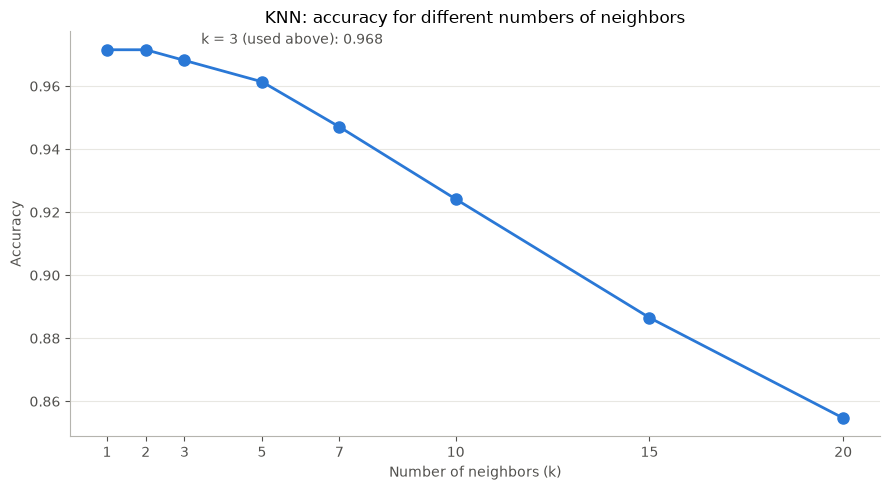

In [21]:
# KNN chart: run the same cross-validation as above for several values of k
k_values = [1, 2, 3, 5, 7, 10, 15, 20]
knn_accuracies = []

for k in k_values:
    knn_k = make_pipeline(TfidfVectorizer(**tfidf_params),
                          KNeighborsClassifier(n_neighbors=k, metric="cosine", weights="distance"))
    predictions = cross_val_predict(knn_k, lyrics, roud, cv=folds)
    knn_accuracies.append(accuracy_score(roud, predictions))

# Draw accuracy against k, and mark the k used by the KNN model above
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_values, knn_accuracies, color="#2a78d6", linewidth=2, marker="o", markersize=8)

accuracy_at_3 = knn_accuracies[k_values.index(3)]
ax.annotate(f"k = 3 (used above): {accuracy_at_3:.3f}", xy=(3, accuracy_at_3), xytext=(12, 12),
            textcoords="offset points", color="#52514e")

ax.set_title("KNN: accuracy for different numbers of neighbors")
ax.set_xticks(k_values)
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Accuracy")
ax.grid(axis="y", color="#e8e7e2")
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("ballad_knn_accuracy_by_k.png", dpi=200)
plt.show()

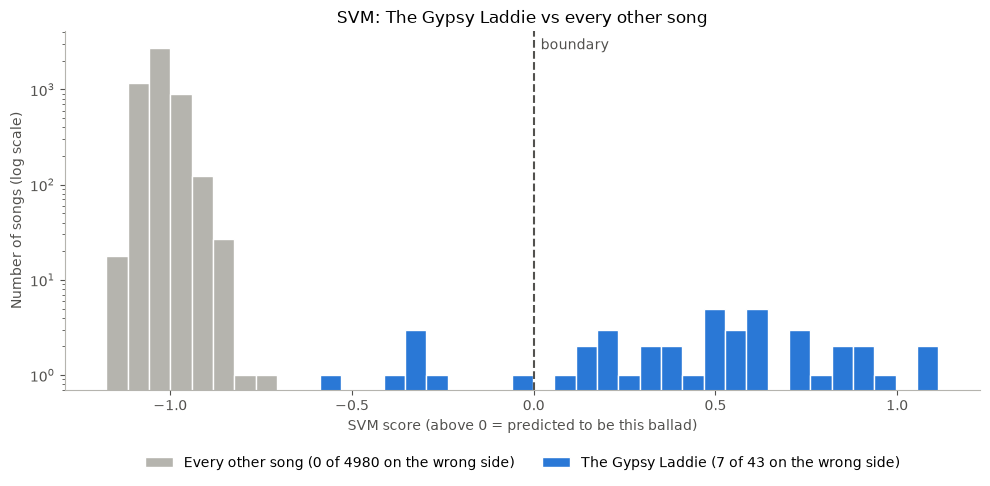

In [22]:
# SVM chart: the SVM above trains one "this ballad or not" boundary per ballad. Here we train just one of those,
# for the largest ballad. Each song's score comes from a model that didn't see that song
chosen_ballad = top_10_ballads[0]
svm_one_ballad = make_pipeline(TfidfVectorizer(**tfidf_params), LinearSVC(random_state=SEED))
svm_scores = cross_val_predict(svm_one_ballad, lyrics, roud == chosen_ballad, cv=folds, method="decision_function")

is_chosen_ballad = roud == chosen_ballad
chosen_scores = svm_scores[is_chosen_ballad]
other_scores = svm_scores[~is_chosen_ballad]

# Count the songs that ended up on the wrong side of the boundary
chosen_wrong_side = (chosen_scores < 0).sum()
other_wrong_side = (other_scores > 0).sum()

# Both groups use the same bins so their bars line up.
# The y axis is logarithmic because the other songs far outnumber this ballad's songs.
bins = np.linspace(svm_scores.min(), svm_scores.max(), 40)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(other_scores, bins=bins, color="#b5b4ae", edgecolor="white", linewidth=1,
        label=f"Every other song ({other_wrong_side} of {len(other_scores)} on the wrong side)")
ax.hist(chosen_scores, bins=bins, color="#2a78d6", edgecolor="white", linewidth=1,
        label=f"{ballad_names[chosen_ballad]} ({chosen_wrong_side} of {len(chosen_scores)} on the wrong side)")
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1.5)
ax.annotate("boundary", xy=(0, 1), xycoords=("data", "axes fraction"), xytext=(5, -5),
            textcoords="offset points", va="top", color="#52514e")

ax.set_yscale("log")
ax.set_ylim(bottom=0.7)
ax.set_title(f"SVM: {ballad_names[chosen_ballad]} vs every other song")
ax.set_xlabel("SVM score (above 0 = predicted to be this ballad)")
ax.set_ylabel("Number of songs (log scale)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=2)

fig.tight_layout()
fig.savefig("ballad_svm_scores.png", dpi=200)
plt.show()

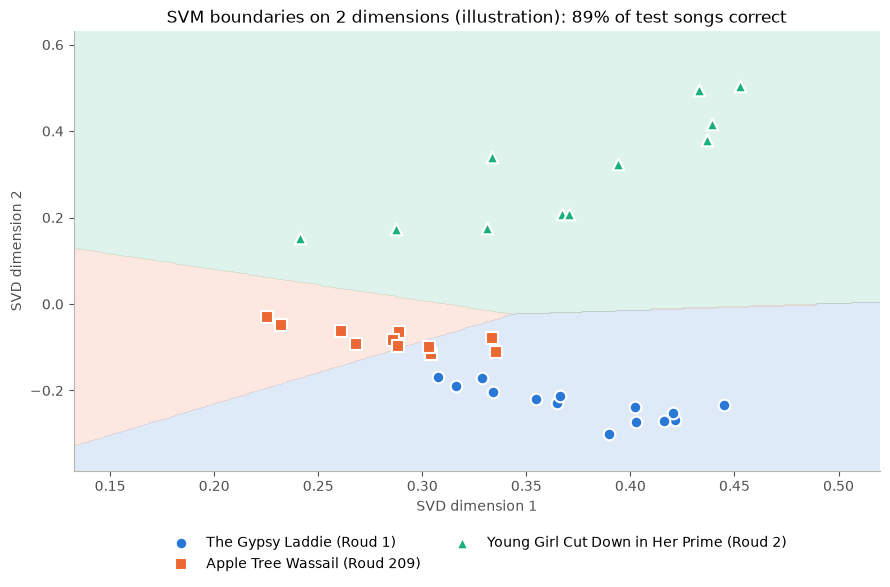

In [23]:
# SVM boundary chart: squash the top 3 ballads down to 2 dimensions with TF-IDF and TruncatedSVD
reducer = make_pipeline(TfidfVectorizer(**tfidf_params), TruncatedSVD(n_components=2, random_state=SEED))
train_points = reducer.fit_transform(lyrics[train_top_3])
test_points = reducer.transform(lyrics[test_top_3])

# Train an SVM on just these 2 dimensions. This is a separate, simpler model than the one scored above
svm_2d = LinearSVC(random_state=SEED)
svm_2d.fit(train_points, train_labels)
accuracy_2d = svm_2d.score(test_points, test_labels)

# Make a grid of points covering the chart, and predict a ballad for every grid point
all_points = np.vstack([train_points, test_points])
x_margin = 0.05 * (all_points[:, 0].max() - all_points[:, 0].min())
y_margin = 0.05 * (all_points[:, 1].max() - all_points[:, 1].min())
x_values = np.linspace(all_points[:, 0].min() - x_margin, all_points[:, 0].max() + x_margin, 400)
y_values = np.linspace(all_points[:, 1].min() - y_margin, all_points[:, 1].max() + y_margin, 400)
grid_x, grid_y = np.meshgrid(x_values, y_values)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
grid_predictions = svm_2d.predict(grid_points)

# The contour function needs numbers, so swap each ballad for its position in the list
grid_numbers = np.zeros(len(grid_predictions))
for position, ballad in enumerate(top_3_ballads):
    grid_numbers[grid_predictions == ballad] = position
grid_numbers = grid_numbers.reshape(grid_x.shape)

# Shade each ballad's region, then draw the test songs on top
region_colors = []
for ballad in top_3_ballads:
    region_colors.append(ballad_colors[ballad])

fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(grid_x, grid_y, grid_numbers, levels=[-0.5, 0.5, 1.5, 2.5], colors=region_colors, alpha=0.15)
draw_songs(ax, test_points, test_labels)
ax.set_title(f"SVM boundaries on 2 dimensions (illustration): {accuracy_2d:.0%} of test songs correct")
ax.set_xlabel("SVD dimension 1")
ax.set_ylabel("SVD dimension 2")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=2)

fig.tight_layout()
fig.savefig("ballad_svm_boundary.png", dpi=200)
plt.show()

In [24]:
# Confusion matrix: each row is a ballad's true songs, each column is what the model predicted
def plot_confusion(name, pred_col):
    # Keep only the songs that truly belong to one of the top 10 ballads
    is_top_10 = np.isin(roud, top_10_ballads)
    true_labels = roud[is_top_10]
    predicted_labels = df_pred[pred_col].to_numpy()[is_top_10]

    # Predictions of any ballad outside the top 10 all go in one "Other" column
    predicted_labels = np.where(np.isin(predicted_labels, top_10_ballads), predicted_labels, "Other")
    column_labels = list(top_10_ballads) + ["Other"]

    # The last row would be for songs whose true ballad is "Other". There are none, so drop it
    matrix = confusion_matrix(true_labels, predicted_labels, labels=column_labels)[:-1]

    row_names = []
    for ballad in top_10_ballads:
        row_names.append(f"{ballad_names[ballad]} ({ballad})")

    fig, ax = plt.subplots(figsize=(11, 6))
    ax.imshow(matrix, cmap="Blues")

    # Write the count in each cell, leaving the zeros blank so the mistakes stand out
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            count = matrix[row, column]
            if count > 0:
                text_color = "white" if count > matrix.max() / 2 else "#0b0b0b"
                ax.text(column, row, count, ha="center", va="center", color=text_color)

    ax.set_xticks(range(len(column_labels)), column_labels)
    ax.set_yticks(range(len(row_names)), row_names)
    ax.set_title(f"{name}: predictions for the 10 largest ballads")
    ax.set_xlabel("Predicted Roud number")
    ax.set_ylabel("True ballad (Roud number)")
    ax.spines[["left", "bottom"]].set_visible(False)

    fig.tight_layout()
    fig.savefig(f"ballad_confusion_{name.lower()}.png", dpi=200)
    plt.show()

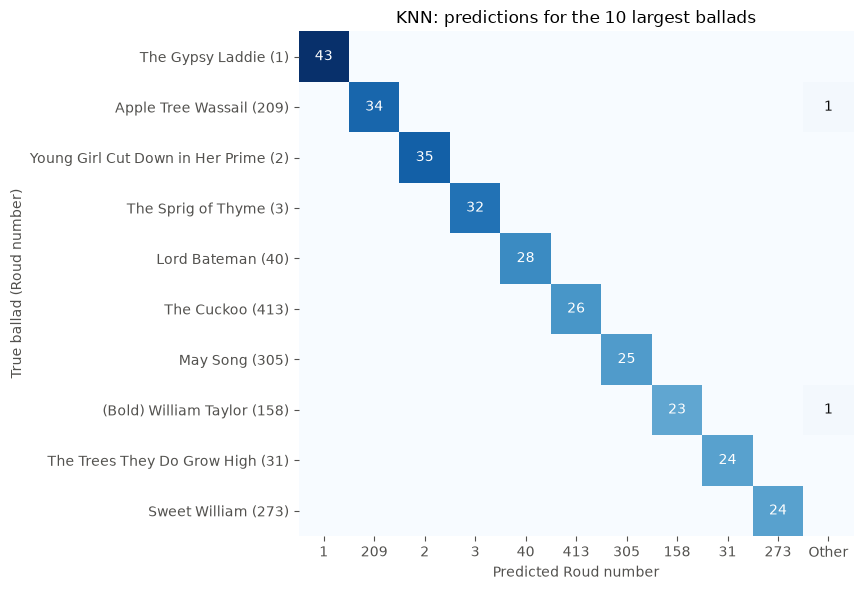

In [25]:
plot_confusion("KNN", "pred_knn")

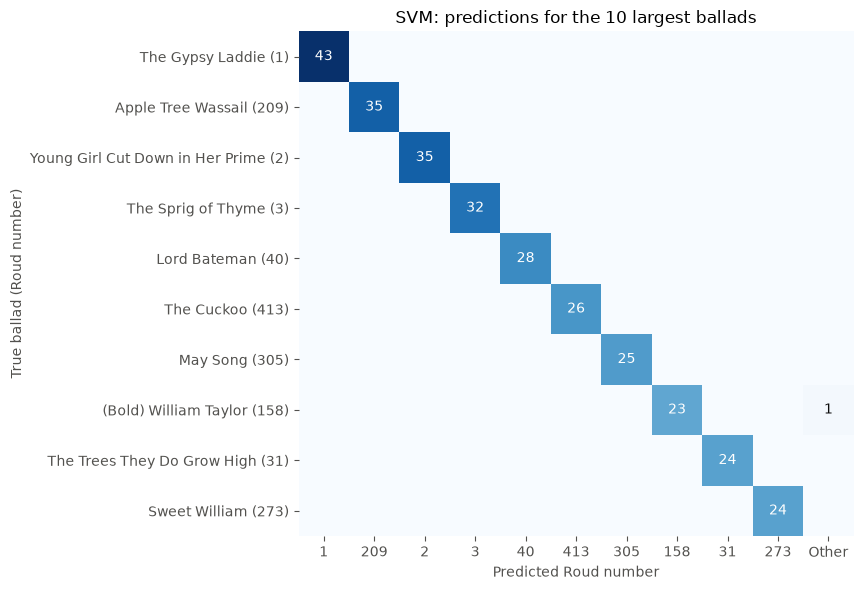

In [26]:
plot_confusion("SVM", "pred_svm")

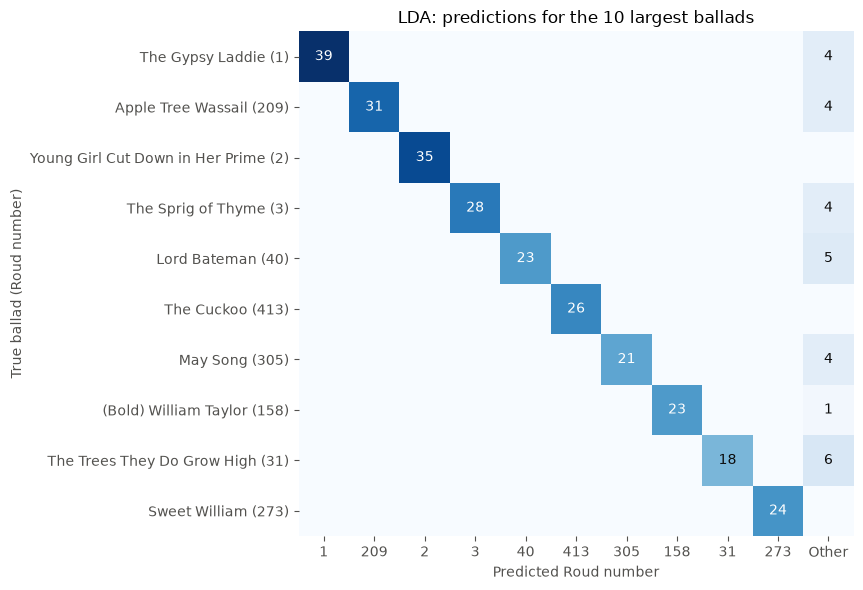

In [27]:
plot_confusion("LDA", "pred_lda")

Each ballad's lyrics were turned into word scores (TF-IDF) over single words and word pairs, as in the clustering notebook.
Instead of looking for groups on their own, KNN, SVM and LDA were shown the Roud numbers of two thirds of the songs and asked to
predict the Roud numbers of the remaining third, repeated until every song had been predicted once. The results table compares each
model with the baseline and with the clustering notebook's metrics. In the charts, orange points are songs the model got wrong, and the histograms show how many ballads reached each F1 score.